# HR Data Analysis

**Organization:** AFAME Technologies  
**Project type:** Data Analyst Internship Project


## Table of Contents
1. [Project Overview](#project-overview)
2. [Data Loading](#data-loading)
3. [Understand HR Data](#understand-hr-data)
4. [Data Quality Analysis](#data-quality-analysis)
5. [Data Cleaning](#data-cleaning)
6. [Feature Engineering](#feature-engineering)
7. [HR Overview](#hr-overview)
8. [Demographics](#employee-demographics-analysis)
9. [Department and Job Role](#department-and-job-role-analysis)
10. [Attrition](#attrition-analysis)
11. [Salary](#salary-and-compensation-analysis)
12. [Satisfaction](#employee-satisfaction-analysis)
13. [Experience](#experience-and-career-growth)
14. [Correlation](#correlation-and-statistical-analysis)
15. [Business Insights](#hr-business-insights)
16. [Recommendations](#hr-recommendations)
17. [Conclusion](#final-conclusion)

## Project Overview
This project examines employee information to understand workforce composition, compensation, satisfaction, experience, and attrition. Clean and reliable HR data helps managers ask better workforce questions and prioritize practical retention actions.

### Problem Statement
The HR record set contains demographic, employment, compensation, satisfaction, and attrition fields. Raw values need validation and organization before they can support trustworthy workforce findings.

### Objectives
- Clean and document the employee dataset.
- Measure workforce composition and attrition.
- Compare departments and job roles.
- Examine overtime, travel, satisfaction, income, and tenure in relation to attrition.
- Provide measurable HR recommendations without overstating causality.

### Dataset Description
The source file is `HR Data.csv` with 35 employee-level fields. It includes demographics, employment details, compensation, satisfaction scores, experience measures, and attrition status.

### Tools and Technologies
Python, pandas, NumPy, Matplotlib, Seaborn, Plotly.

### Analysis Workflow
Load -> understand fields -> assess quality -> clean -> engineer categories -> analyze workforce patterns -> interpret attrition -> save outputs.


## Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 110
})


## Data Loading

In [2]:

NOTEBOOK_DIR = Path.cwd()
project_root = next((p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
                     if (p / "HR Data.csv").exists()), None)
assert project_root is not None, "Could not locate HR Data.csv"

hr_file = project_root / "HR Data.csv"
raw_hr = pd.read_csv(hr_file)
display(raw_hr.head())
display(raw_hr.tail())
display(raw_hr.sample(5, random_state=42))
print("Shape:", raw_hr.shape)
print("Columns:", raw_hr.columns.tolist())
print("Data types:")
display(raw_hr.dtypes.to_frame("data_type"))
raw_hr.info()
display(raw_hr.describe(include="number").T)
display(raw_hr.describe(include="object").T)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1041,28,No,Travel_Rarely,866,Sales,5,3,Medical,1,1469,...,4,80,0,6,4,3,5,4,1,3
184,53,No,Travel_Rarely,1084,Research & Development,13,2,Medical,1,250,...,3,80,2,5,3,3,4,2,1,3
1222,24,Yes,Travel_Rarely,240,Human Resources,22,1,Human Resources,1,1714,...,3,80,1,1,2,3,1,0,0,0
67,45,No,Travel_Rarely,1339,Research & Development,7,3,Life Sciences,1,86,...,3,80,1,25,2,3,1,0,0,0
220,36,No,Travel_Rarely,1396,Research & Development,5,2,Life Sciences,1,304,...,4,80,0,16,3,4,13,11,3,7


Shape: (1470, 35)
Columns: ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Data types:


,data_type
Age,int64
Attrition,str
BusinessTravel,str
DailyRate,int64
Department,str
DistanceFromHome,int64
Education,int64
EducationField,str
EmployeeCount,int64
EmployeeNumber,int64


<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


C:\Users\gp298\AppData\Local\Temp\ipykernel_8864\619765669.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw_hr.describe(include="object").T)


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


## Understand HR Data

In [3]:

column_groups = {
    "Employee demographics": ["Age","Gender","MaritalStatus","Education","EducationField"],
    "Employment information": ["Department","JobRole","JobLevel","BusinessTravel","EmployeeNumber"],
    "Compensation": ["DailyRate","HourlyRate","MonthlyIncome","MonthlyRate","PercentSalaryHike"],
    "Employee experience": ["TotalWorkingYears","YearsAtCompany","YearsInCurrentRole","YearsWithCurrManager","YearsSinceLastPromotion"],
    "Employee satisfaction": ["EnvironmentSatisfaction","JobSatisfaction","JobInvolvement","RelationshipSatisfaction","WorkLifeBalance"],
    "Employment status": ["Attrition","OverTime","PerformanceRating","NumCompaniesWorked"],
}
for group, columns in column_groups.items():
    print(f"{group}: {', '.join(columns)}")

cardinality_hr = pd.DataFrame({
    "unique_values": raw_hr.nunique(dropna=True),
    "missing_values": raw_hr.isna().sum(),
    "data_type": raw_hr.dtypes.astype(str)
}).sort_index()
display(cardinality_hr)


Employee demographics: Age, Gender, MaritalStatus, Education, EducationField
Employment information: Department, JobRole, JobLevel, BusinessTravel, EmployeeNumber
Compensation: DailyRate, HourlyRate, MonthlyIncome, MonthlyRate, PercentSalaryHike
Employee experience: TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsWithCurrManager, YearsSinceLastPromotion
Employee satisfaction: EnvironmentSatisfaction, JobSatisfaction, JobInvolvement, RelationshipSatisfaction, WorkLifeBalance
Employment status: Attrition, OverTime, PerformanceRating, NumCompaniesWorked


,unique_values,missing_values,data_type
Age,43,0,int64
Attrition,2,0,str
BusinessTravel,3,0,str
DailyRate,886,0,int64
Department,3,0,str
DistanceFromHome,29,0,int64
Education,5,0,int64
EducationField,6,0,str
EmployeeCount,1,0,int64
EmployeeNumber,1470,0,int64



Satisfaction fields are ordinal ratings. They describe ordered categories, but their numeric values should not automatically be interpreted as a continuous scale in every analysis.

## Data Quality Analysis


In [4]:

missing_hr = raw_hr.isna().sum()
display(pd.DataFrame({
    "missing_count": missing_hr,
    "missing_percent": (missing_hr / len(raw_hr) * 100).round(2)
}).sort_values("missing_count", ascending=False))
print("Exact duplicate rows:", int(raw_hr.duplicated().sum()))
print("Duplicate EmployeeNumber rows:", int(raw_hr["EmployeeNumber"].duplicated().sum()))
print("Invalid ages:", int(((raw_hr["Age"] < 18) | (raw_hr["Age"] > 100)).sum()))
print("Invalid MonthlyIncome:", int((raw_hr["MonthlyIncome"] <= 0).sum()))

constant_columns = [c for c in raw_hr.columns if raw_hr[c].nunique(dropna=False) == 1]
print("Constant columns:", constant_columns)

categorical_columns = raw_hr.select_dtypes(include=["object", "category"]).columns
for column in categorical_columns:
    print(f"{column}: {sorted(raw_hr[column].dropna().astype(str).unique().tolist())}")


,missing_count,missing_percent
Age,0,0.0
StandardHours,0,0.0
NumCompaniesWorked,0,0.0
Over18,0,0.0
OverTime,0,0.0
PercentSalaryHike,0,0.0
PerformanceRating,0,0.0
RelationshipSatisfaction,0,0.0
StockOptionLevel,0,0.0
MonthlyIncome,0,0.0


Exact duplicate rows: 0
Duplicate EmployeeNumber rows: 0
Invalid ages: 0
Invalid MonthlyIncome: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Attrition: ['No', 'Yes']
BusinessTravel: ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department: ['Human Resources', 'Research & Development', 'Sales']
EducationField: ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender: ['Female', 'Male']
JobRole: ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus: ['Divorced', 'Married', 'Single']
Over18: ['Y']
OverTime: ['No', 'Yes']


C:\Users\gp298\AppData\Local\Temp\ipykernel_8864\2855332823.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = raw_hr.select_dtypes(include=["object", "category"]).columns



The dataset has no missing values or exact duplicate rows, so no artificial missing-value treatment is needed. `EmployeeCount` and `StandardHours` are constant. `Over18` is constant as Y and `EmployeeNumber` is a unique identifier. These fields are excluded from analytical summaries because they add no employee-level variation.

## Data Cleaning


In [5]:

hr_clean = raw_hr.copy()
hr_clean = hr_clean.drop(columns=["EmployeeCount", "Over18", "StandardHours"])

rename_map = {
    "BusinessTravel": "Business Travel",
    "DailyRate": "Daily Rate",
    "DistanceFromHome": "Distance From Home",
    "EducationField": "Education Field",
    "EmployeeNumber": "Employee Number",
    "EnvironmentSatisfaction": "Environment Satisfaction",
    "HourlyRate": "Hourly Rate",
    "JobInvolvement": "Job Involvement",
    "JobLevel": "Job Level",
    "JobRole": "Job Role",
    "JobSatisfaction": "Job Satisfaction",
    "MaritalStatus": "Marital Status",
    "MonthlyIncome": "Monthly Income",
    "MonthlyRate": "Monthly Rate",
    "NumCompaniesWorked": "Companies Worked",
    "PercentSalaryHike": "Percent Salary Hike",
    "PerformanceRating": "Performance Rating",
    "RelationshipSatisfaction": "Relationship Satisfaction",
    "StockOptionLevel": "Stock Option Level",
    "TotalWorkingYears": "Total Working Years",
    "TrainingTimesLastYear": "Training Times Last Year",
    "WorkLifeBalance": "Work-Life Balance",
    "YearsAtCompany": "Years at Company",
    "YearsInCurrentRole": "Years in Current Role",
    "YearsSinceLastPromotion": "Years Since Last Promotion",
    "YearsWithCurrManager": "Years with Current Manager",
}
hr_clean = hr_clean.rename(columns=rename_map)

for column in hr_clean.select_dtypes(include=["object", "category"]).columns:
    hr_clean[column] = hr_clean[column].astype("string").str.strip()

for column in hr_clean.columns:
    if hr_clean[column].dtype == "object":
        hr_clean[column] = hr_clean[column].astype("string")

print("Original shape:", raw_hr.shape)
print("Cleaned shape:", hr_clean.shape)
print("Removed constant/identifier fields:", ["EmployeeCount","Over18","StandardHours","Employee Number"])
print("Remaining missing values:", int(hr_clean.isna().sum().sum()))
print("Remaining duplicate rows:", int(hr_clean.duplicated().sum()))
assert hr_clean["Age"].between(18, 100).all()
assert hr_clean["Monthly Income"].gt(0).all()
assert hr_clean["Employee Number"].nunique() == len(hr_clean)
display(hr_clean.dtypes.to_frame("data_type"))


Original shape: (1470, 35)
Cleaned shape: (1470, 32)
Removed constant/identifier fields: ['EmployeeCount', 'Over18', 'StandardHours', 'Employee Number']
Remaining missing values: 0
Remaining duplicate rows: 0


C:\Users\gp298\AppData\Local\Temp\ipykernel_8864\1952390469.py:34: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in hr_clean.select_dtypes(include=["object", "category"]).columns:


,data_type
Age,int64
Attrition,string
Business Travel,string
Daily Rate,int64
Department,string
Distance From Home,int64
Education,int64
Education Field,string
Employee Number,int64
Environment Satisfaction,int64



The original CSV was not changed. The cleaned frame removes constant administrative fields that do not support employee-level comparisons and renames long fields into readable names. `Employee Number` remains in the cleaned data as an identifier, although it is no longer used as an analytical category.

## Feature Engineering


In [6]:

hr_clean["Age Group"] = pd.cut(hr_clean["Age"], bins=[17, 25, 35, 45, 55, 100],
                               labels=["18-25","26-35","36-45","46-55","56+"])
hr_clean["Tenure Group"] = pd.cut(hr_clean["Years at Company"],
                                  bins=[-1, 2, 5, 10, 40],
                                  labels=["0-2 years","3-5 years","6-10 years","11+ years"])
hr_clean["Income Group"] = pd.qcut(hr_clean["Monthly Income"], q=4,
                                   labels=["Q1 Low","Q2","Q3","Q4 High"])
hr_clean["Experience Group"] = pd.cut(hr_clean["Total Working Years"],
                                      bins=[-1, 5, 10, 20, 60],
                                      labels=["0-5 years","6-10 years","11-20 years","21+ years"])

display(pd.DataFrame({
    "Feature":["Age Group","Tenure Group","Income Group","Experience Group"],
    "Purpose":["Compare life-stage workforce patterns","Compare tenure-based patterns",
               "Compare compensation quartiles","Compare career experience levels"]
}))


,Feature,Purpose
0,Age Group,Compare life-stage workforce patterns
1,Tenure Group,Compare tenure-based patterns
2,Income Group,Compare compensation quartiles
3,Experience Group,Compare career experience levels


The derived groups reduce noise from individual values. Income groups use quartiles, while age and experience groups use practical ranges.

## HR Overview

In [7]:

total_employees = len(hr_clean)
attrition_count = (hr_clean["Attrition"] == "Yes").sum()
attrition_rate = attrition_count / total_employees * 100
department_counts = hr_clean["Department"].value_counts().rename_axis("Department").reset_index(name="Employees")
gender_counts = hr_clean["Gender"].value_counts().rename_axis("Gender").reset_index(name="Employees")

overview = pd.DataFrame({
    "Metric":["Total Employees","Employees in Department","Average Age","Average Monthly Income",
              "Average Years at Company","Attrition Count","Attrition Rate",
              "Average Job Satisfaction","Average Work-Life Balance","Average Performance Rating"],
    "Value":[total_employees, department_counts["Employees"].sum(),
             hr_clean["Age"].mean(), hr_clean["Monthly Income"].mean(),
             hr_clean["Years at Company"].mean(), attrition_count, attrition_rate,
             hr_clean["Job Satisfaction"].mean(), hr_clean["Work-Life Balance"].mean(),
             hr_clean["Performance Rating"].mean()]
})
display(overview)
display(department_counts)
display(gender_counts)


,Metric,Value
0,Total Employees,1470.000000
1,Employees in Department,1470.000000
2,Average Age,36.923810
3,Average Monthly Income,6502.931293
4,Average Years at Company,7.008163
5,Attrition Count,237.000000
6,Attrition Rate,16.122449
7,Average Job Satisfaction,2.728571
8,Average Work-Life Balance,2.761224
9,Average Performance Rating,3.153741


,Department,Employees
0,Research & Development,961
1,Sales,446
2,Human Resources,63


,Gender,Employees
0,Male,882
1,Female,588


## Employee Demographics Analysis

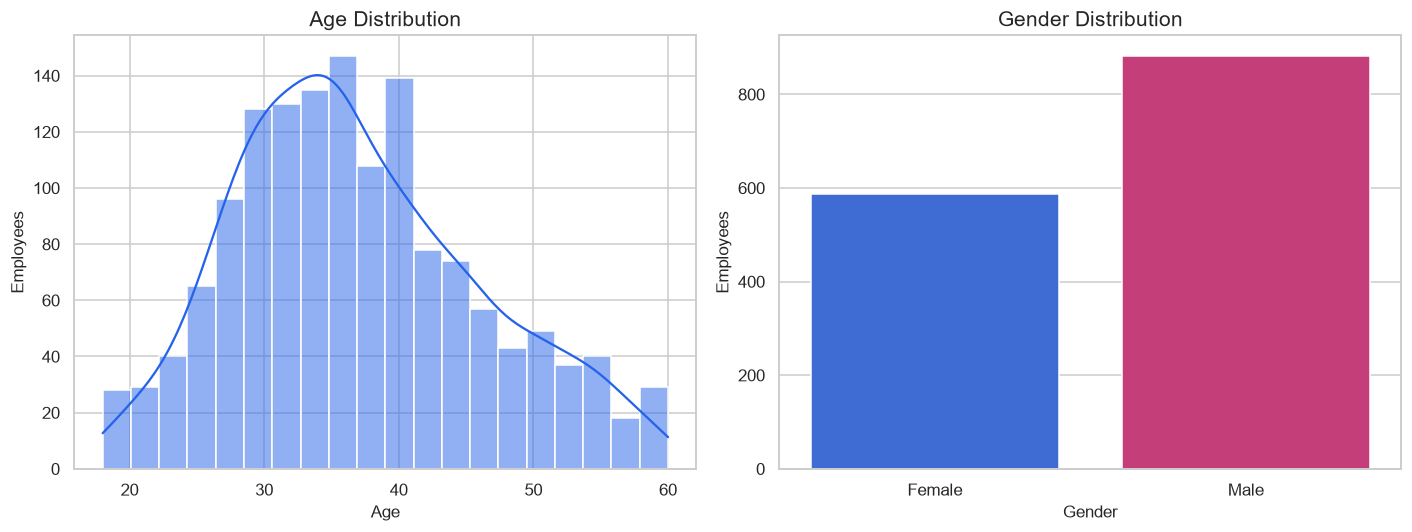

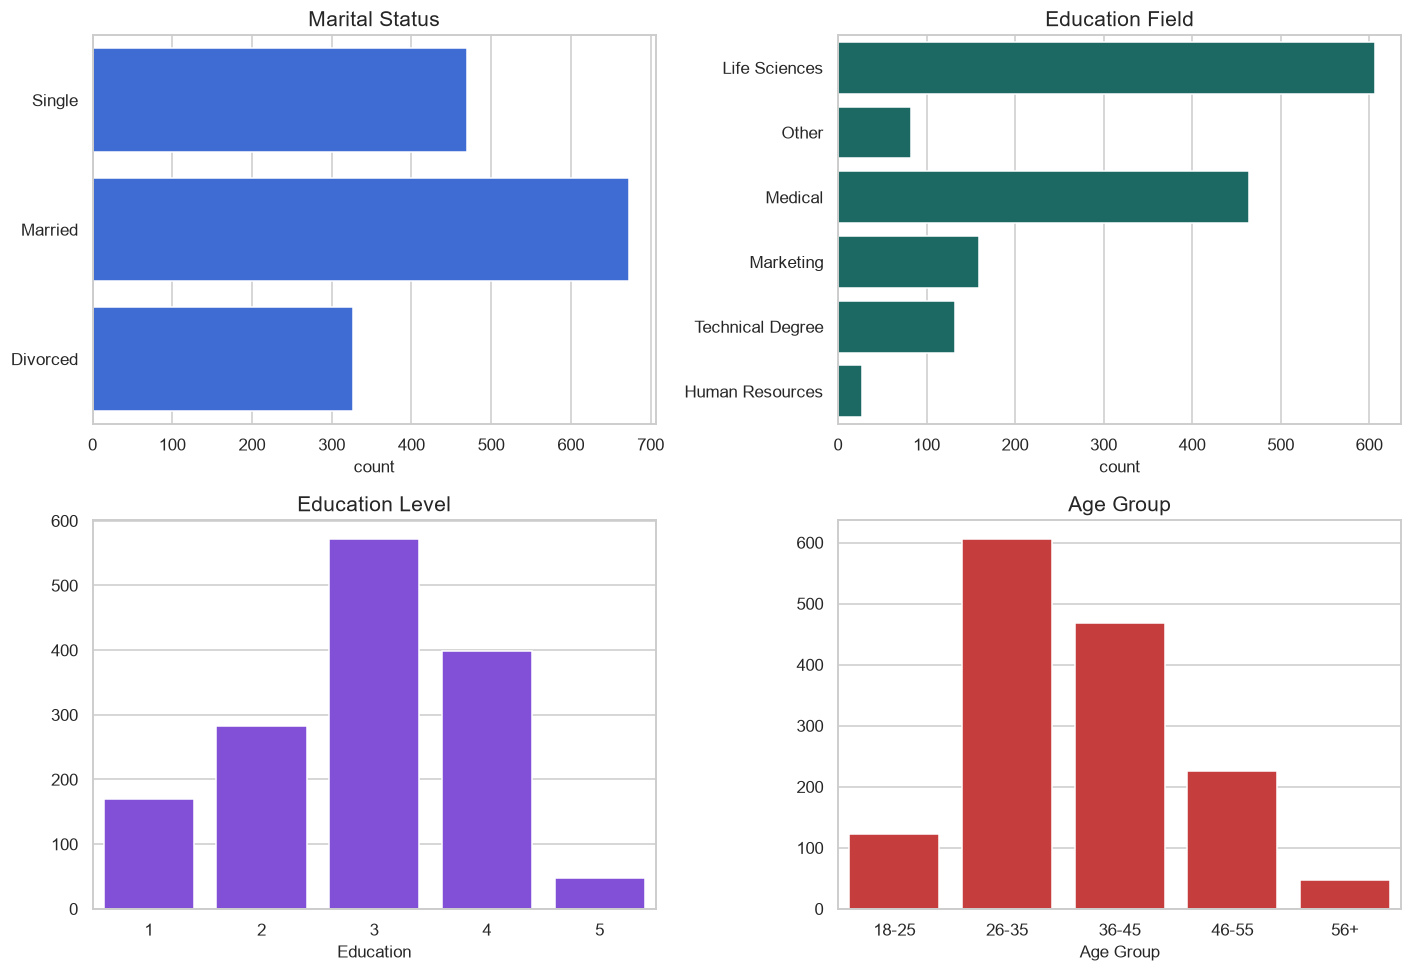

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(hr_clean["Age"], bins=20, kde=True, ax=axes[0], color="#2563eb")
sns.countplot(data=hr_clean, x="Gender", ax=axes[1], palette=["#2563eb","#db2777"])
axes[0].set(title="Age Distribution", xlabel="Age", ylabel="Employees")
axes[1].set(title="Gender Distribution", xlabel="Gender", ylabel="Employees")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "age_gender_distribution.png")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=hr_clean, y="Marital Status", ax=axes[0,0], color="#2563eb")
sns.countplot(data=hr_clean, y="Education Field", ax=axes[0,1], color="#0f766e")
sns.countplot(data=hr_clean, x="Education", ax=axes[1,0], color="#7c3aed")
sns.countplot(data=hr_clean, x="Age Group", ax=axes[1,1], color="#dc2626")
for ax in axes.flat:
    ax.set_ylabel("")
axes[0,0].set_title("Marital Status")
axes[0,1].set_title("Education Field")
axes[1,0].set_title("Education Level")
axes[1,1].set_title("Age Group")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "demographics.png")
plt.show()


The age and demographic distributions show workforce composition. They do not by themselves explain employee decisions or identify protected-group disparities without additional legal and statistical review.

## Department and Job Role Analysis

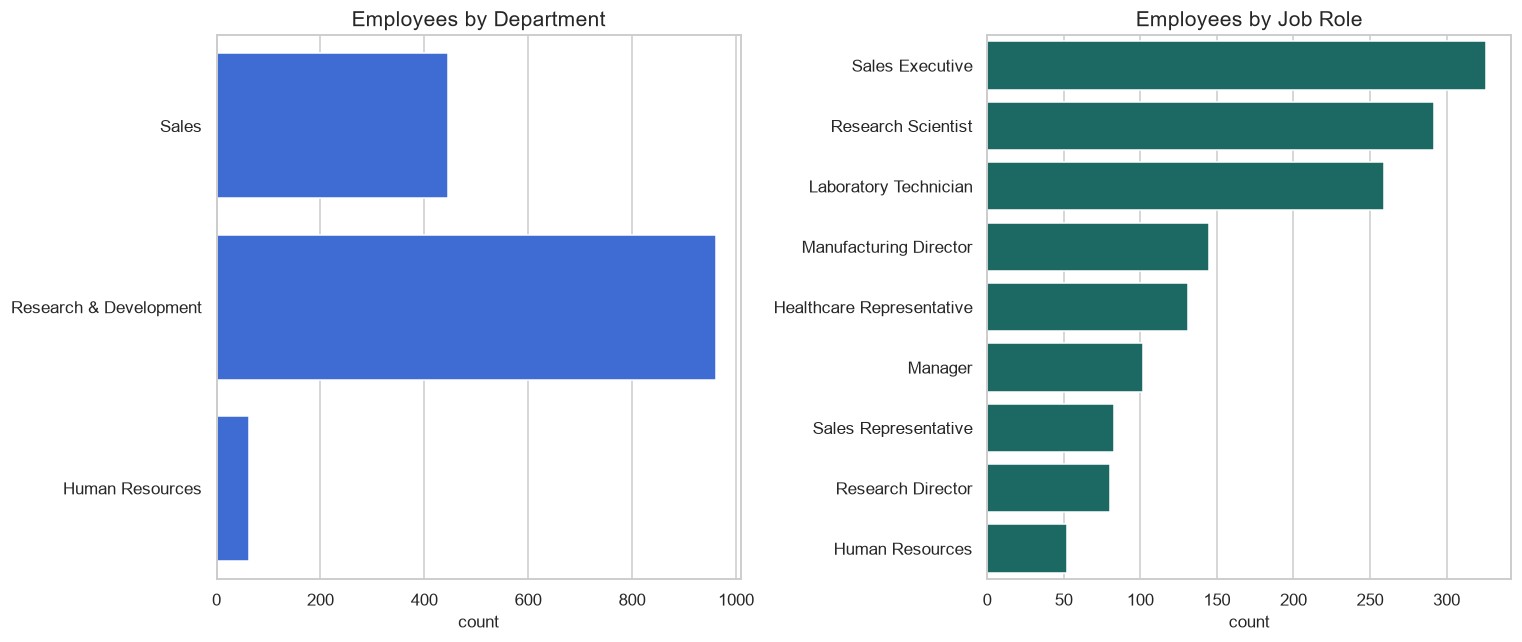

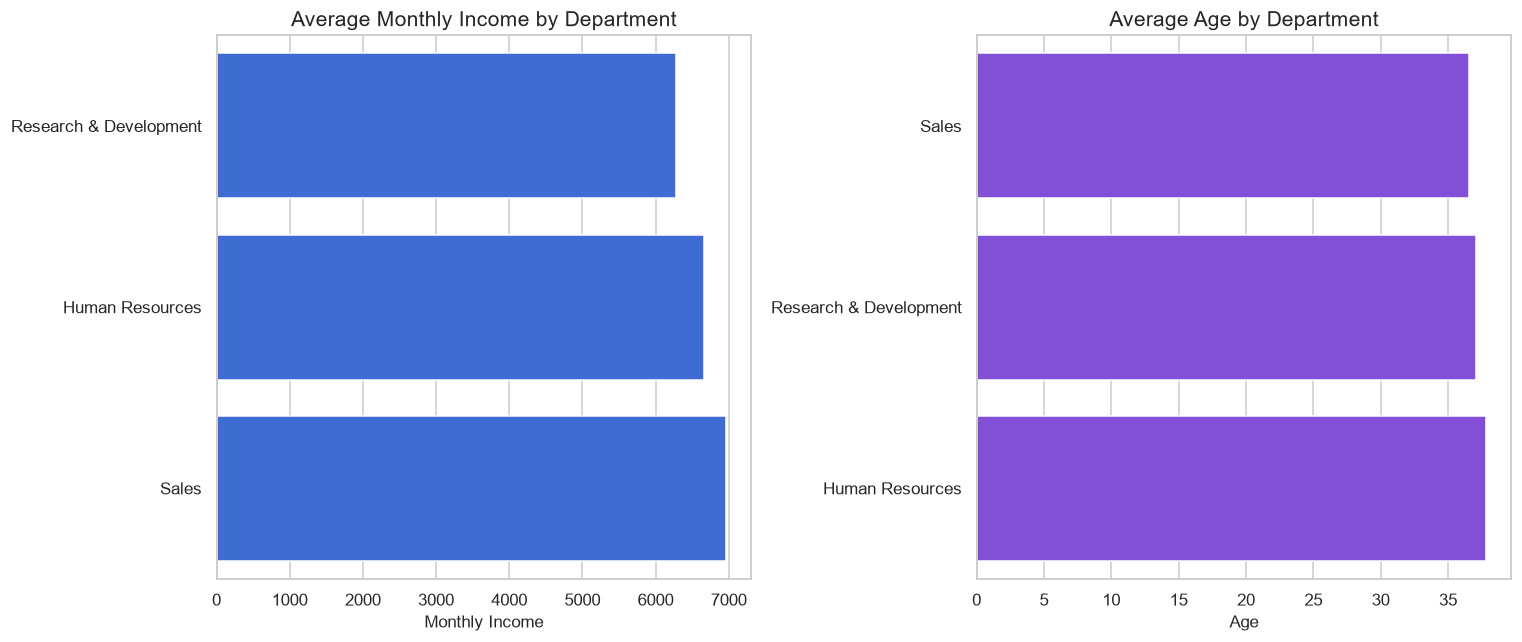

,Department,Monthly Income
1,Research & Development,6281.252862
0,Human Resources,6654.507937
2,Sales,6959.172646


,Job Role,Monthly Income
8,Sales Representative,2626.000000
2,Laboratory Technician,3237.169884
6,Research Scientist,3239.972603
1,Human Resources,4235.750000
7,Sales Executive,6924.279141
4,Manufacturing Director,7295.137931
0,Healthcare Representative,7528.763359
5,Research Director,16033.550000
3,Manager,17181.676471


,Department,Age
2,Sales,36.542601
1,Research & Development,37.042664
0,Human Resources,37.809524


,Department,Total Working Years
2,Sales,11.105381
1,Research & Development,11.342352
0,Human Resources,11.555556


In [9]:

department_salary = hr_clean.groupby("Department", as_index=False)["Monthly Income"].mean().sort_values("Monthly Income")
role_salary = hr_clean.groupby("Job Role", as_index=False)["Monthly Income"].mean().sort_values("Monthly Income")
department_age = hr_clean.groupby("Department", as_index=False)["Age"].mean().sort_values("Age")
department_exp = hr_clean.groupby("Department", as_index=False)["Total Working Years"].mean().sort_values("Total Working Years")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.countplot(data=hr_clean, y="Department", ax=axes[0], color="#2563eb")
sns.countplot(data=hr_clean, y="Job Role", ax=axes[1], color="#0f766e")
axes[0].set_title("Employees by Department")
axes[1].set_title("Employees by Job Role")
axes[0].set_ylabel("")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "department_job_role.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=department_salary, y="Department", x="Monthly Income", ax=axes[0], color="#2563eb")
sns.barplot(data=department_age, y="Department", x="Age", ax=axes[1], color="#7c3aed")
axes[0].set_title("Average Monthly Income by Department")
axes[1].set_title("Average Age by Department")
for ax in axes: ax.set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "department_compensation_age.png")
plt.show()

display(department_salary)
display(role_salary)
display(department_age)
display(department_exp)


Department and role summaries provide average compensation and experience, but averages can hide variation and should be read alongside job level.

## Attrition Analysis

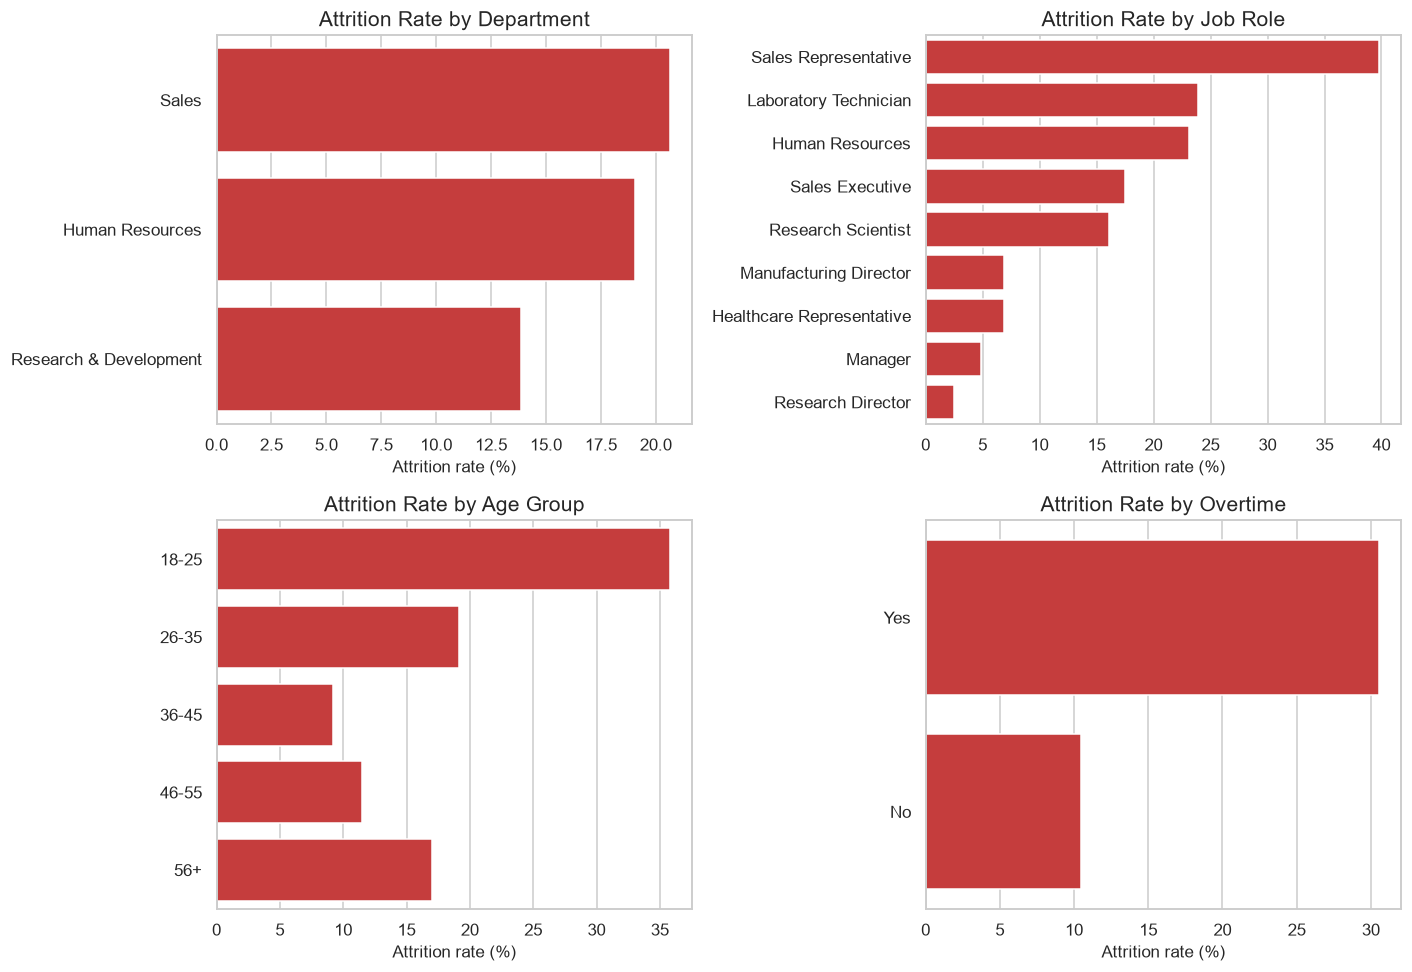

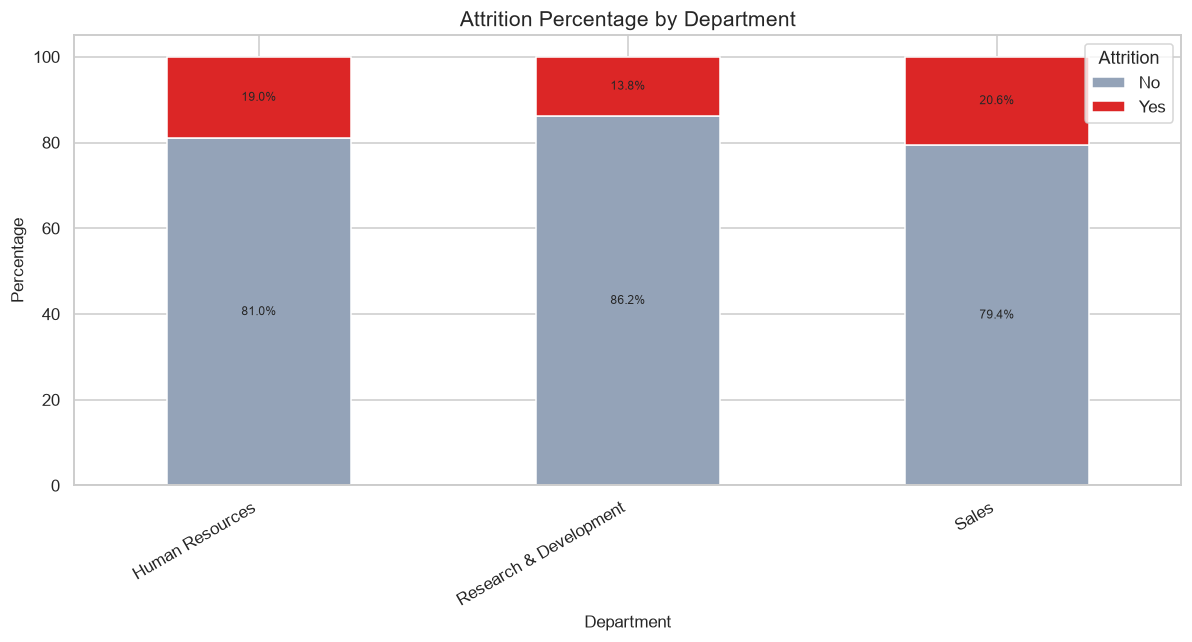

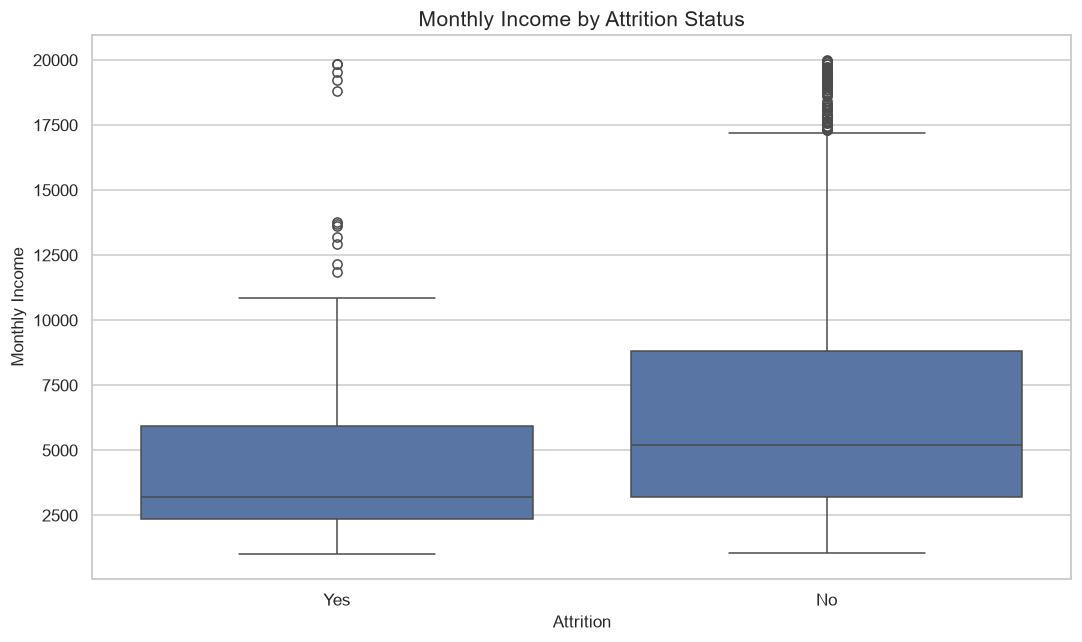

Department


,Department,employees,attrition_count,attrition_rate
2,Sales,446,92,20.627803
0,Human Resources,63,12,19.047619
1,Research & Development,961,133,13.839750


Gender


,Gender,employees,attrition_count,attrition_rate
1,Male,882,150,17.006803
0,Female,588,87,14.795918


Age Group


,Age Group,employees,attrition_count,attrition_rate
0,18-25,123,44,35.772358
1,26-35,606,116,19.141914
4,56+,47,8,17.021277
3,46-55,226,26,11.504425
2,36-45,468,43,9.188034


... (8 outputs left out)

Job satisfaction


,Job Satisfaction,employees,attrition_count,attrition_rate
0,1,289,66,22.837370
2,3,442,73,16.515837
1,2,280,46,16.428571
3,4,459,52,11.328976


Work-life balance


,Work-Life Balance,employees,attrition_count,attrition_rate
0,1,80,25,31.250000
3,4,153,27,17.647059
1,2,344,58,16.860465
2,3,893,127,14.221725


In [10]:

def attrition_rate_table(column):
    table = hr_clean.groupby(column, observed=True)["Attrition"].agg(
        employees="size",
        attrition_count=lambda s: (s == "Yes").sum()
    ).reset_index()
    table["attrition_rate"] = table["attrition_count"] / table["employees"] * 100
    return table.sort_values("attrition_rate", ascending=False)

dept_attrition = attrition_rate_table("Department")
gender_attrition = attrition_rate_table("Gender")
age_attrition = attrition_rate_table("Age Group")
role_attrition = attrition_rate_table("Job Role")
marital_attrition = attrition_rate_table("Marital Status")
overtime_attrition = attrition_rate_table("OverTime")
travel_attrition = attrition_rate_table("Business Travel")
job_sat_attrition = attrition_rate_table("Job Satisfaction")
wlb_attrition = attrition_rate_table("Work-Life Balance")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
crosses = [
    (dept_attrition, "Department", "Department"),
    (role_attrition, "Job Role", "Job Role"),
    (age_attrition, "Age Group", "Age Group"),
    (overtime_attrition, "OverTime", "Overtime"),
]
for ax, (table, col, title) in zip(axes.flat, crosses):
    sns.barplot(data=table, y=col, x="attrition_rate", ax=ax, color="#dc2626")
    ax.set_title(f"Attrition Rate by {title}")
    ax.set_xlabel("Attrition rate (%)")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "attrition_comparisons.png")
plt.show()

stacked = pd.crosstab(hr_clean["Department"], hr_clean["Attrition"], normalize="index") * 100
stacked = stacked.reindex(columns=["No", "Yes"], fill_value=0)
fig, ax = plt.subplots(figsize=(11, 6))
stacked.plot(kind="bar", stacked=True, ax=ax, color=["#94a3b8", "#dc2626"])
ax.set(title="Attrition Percentage by Department", xlabel="Department", ylabel="Percentage")
ax.legend(title="Attrition")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=8)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "department_attrition_percentage_stacked.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=hr_clean, x="Attrition", y="Monthly Income", ax=ax)
ax.set(title="Monthly Income by Attrition Status", xlabel="Attrition", ylabel="Monthly Income")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "income_by_attrition.png")
plt.show()

for name, table in [
    ("Department", dept_attrition), ("Gender", gender_attrition), ("Age Group", age_attrition),
    ("Job Role", role_attrition), ("Marital status", marital_attrition),
    ("Overtime", overtime_attrition), ("Business travel", travel_attrition),
    ("Job satisfaction", job_sat_attrition), ("Work-life balance", wlb_attrition),
]:
    print(name)
    display(table)


Attrition rates use the employees in each group as the denominator. Counts and percentages are not interchangeable. These differences are associations in a cross-sectional employee dataset and do not prove why employees leave.

## Salary and Compensation Analysis

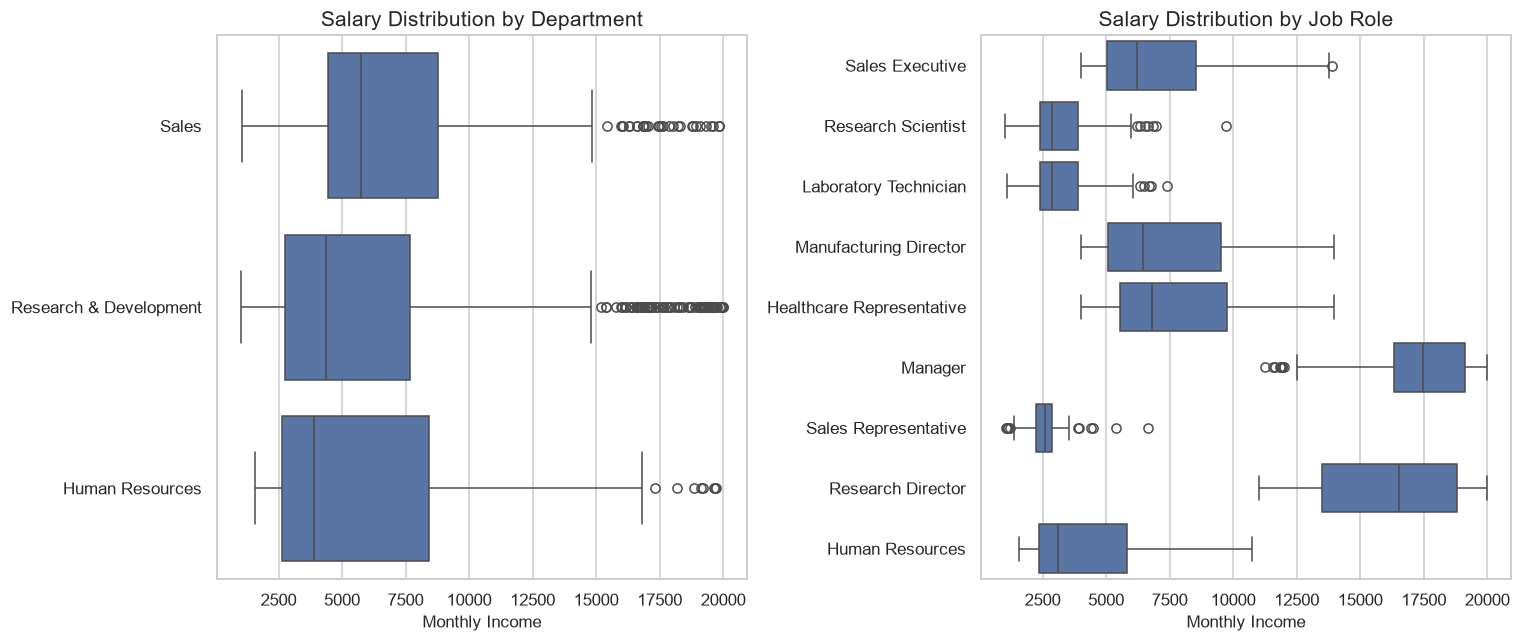

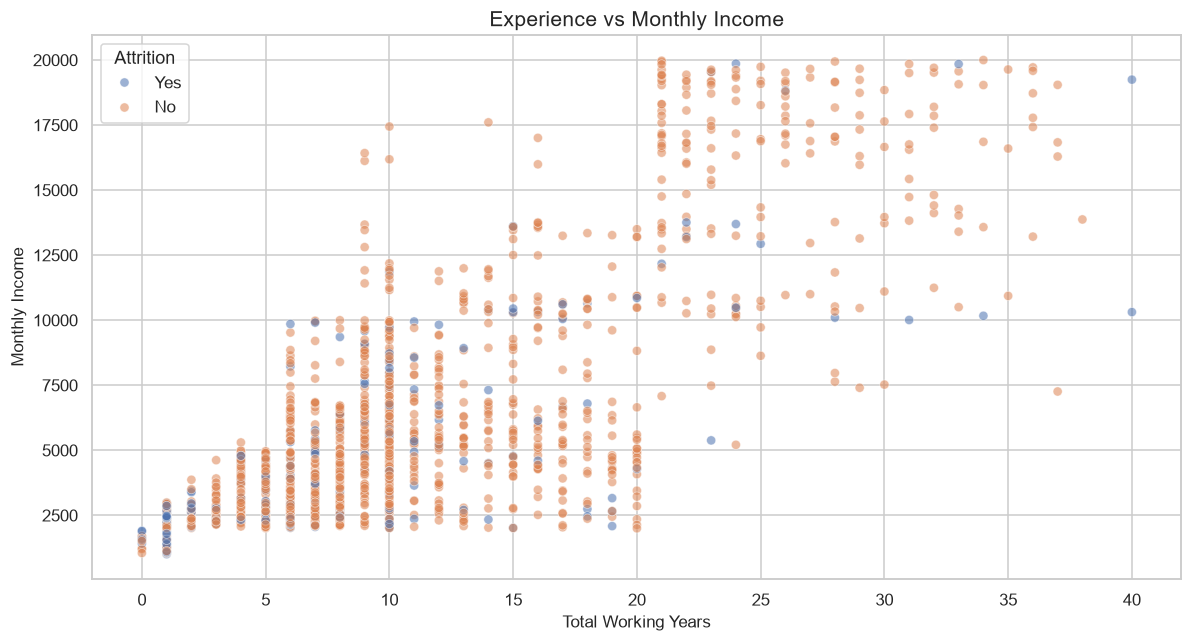

,Job Role,Monthly Income
3,Manager,17181.676471
5,Research Director,16033.550000
0,Healthcare Representative,7528.763359
4,Manufacturing Director,7295.137931
7,Sales Executive,6924.279141
1,Human Resources,4235.750000
6,Research Scientist,3239.972603
2,Laboratory Technician,3237.169884
8,Sales Representative,2626.000000


,Job Level,Monthly Income
0,1,2786.915285
1,2,5502.277154
2,3,9817.252294
3,4,15503.783019
4,5,19191.826087


,Age Group,Monthly Income
0,18-25,2972.886179
1,26-35,4895.633663
2,36-45,7104.444444
3,46-55,10927.960177
4,56+,9197.680851


,Department,Percent Salary Hike
0,Human Resources,14.761905
2,Sales,15.096413
1,Research & Development,15.291363


In [11]:

job_role_salary = hr_clean.groupby("Job Role", as_index=False)["Monthly Income"].mean().sort_values("Monthly Income", ascending=False)
job_level_salary = hr_clean.groupby("Job Level", as_index=False)["Monthly Income"].mean().sort_values("Job Level")
salary_age = hr_clean.groupby("Age Group", observed=True, as_index=False)["Monthly Income"].mean()
salary_hike_department = hr_clean.groupby("Department", as_index=False)["Percent Salary Hike"].mean().sort_values("Percent Salary Hike")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=hr_clean, y="Department", x="Monthly Income", ax=axes[0])
sns.boxplot(data=hr_clean, y="Job Role", x="Monthly Income", ax=axes[1])
axes[0].set_title("Salary Distribution by Department")
axes[1].set_title("Salary Distribution by Job Role")
axes[0].set_ylabel("")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "salary_distribution.png")
plt.show()

fig, ax = plt.subplots()
sns.scatterplot(data=hr_clean, x="Total Working Years", y="Monthly Income", hue="Attrition", alpha=0.55, ax=ax)
ax.set(title="Experience vs Monthly Income")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "experience_vs_income.png")
plt.show()

display(job_role_salary)
display(job_level_salary)
display(salary_age)
display(salary_hike_department)


The compensation charts show average and distributional differences. The data does not establish pay fairness or discrimination by itself.

## Employee Satisfaction Analysis

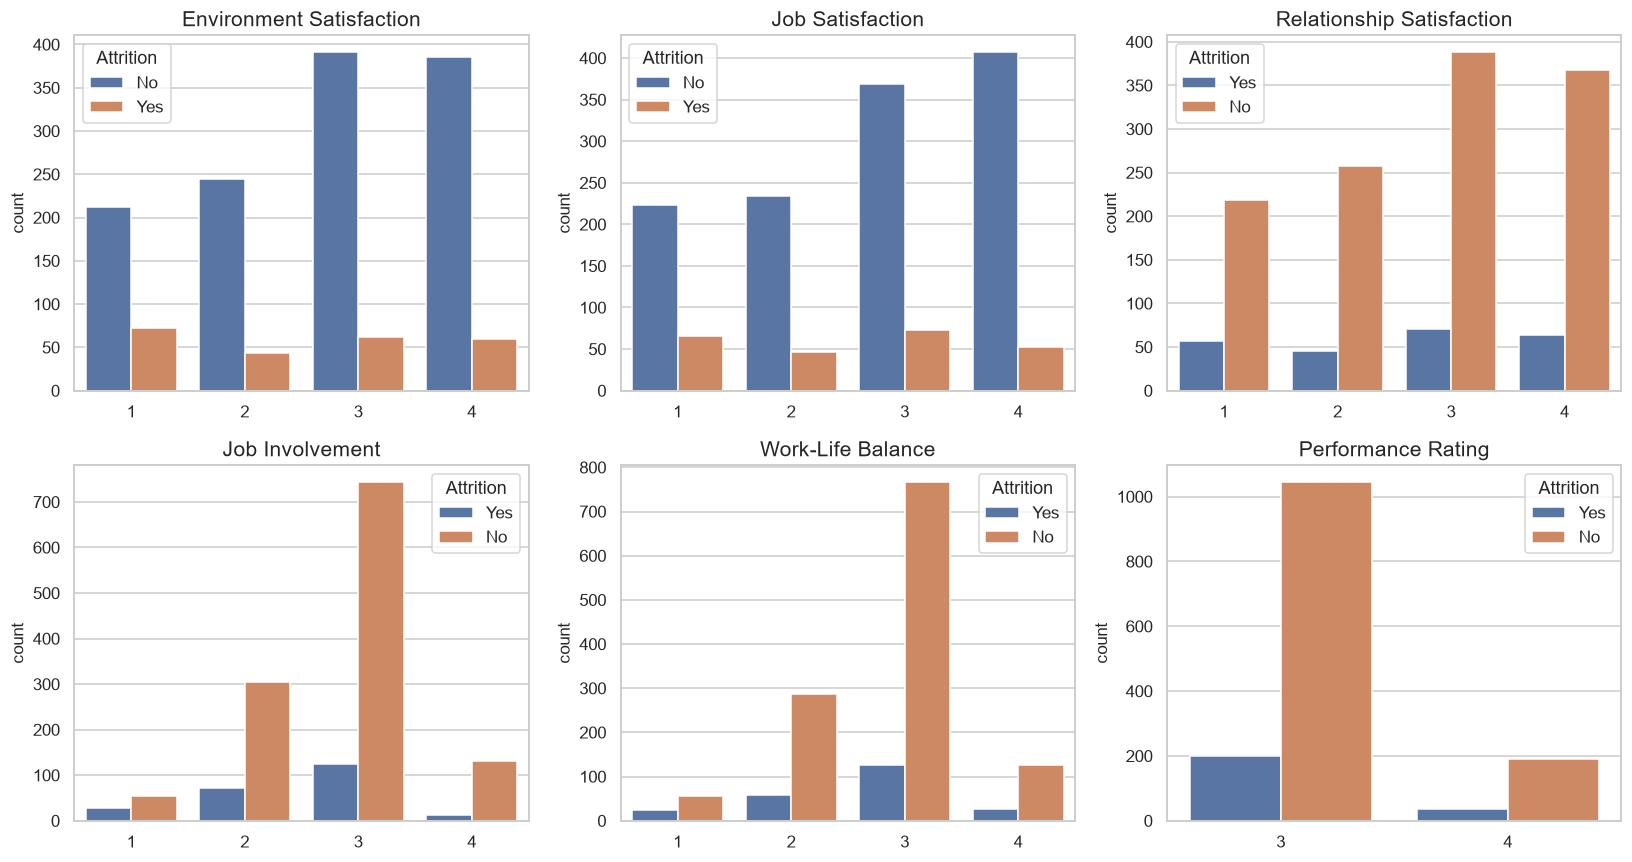

,mean,median
Environment Satisfaction,2.721769,3.0
Job Satisfaction,2.728571,3.0
Relationship Satisfaction,2.712245,3.0
Job Involvement,2.729932,3.0
Work-Life Balance,2.761224,3.0
Performance Rating,3.153741,3.0


,Training Times Last Year,employees,attrition_count,attrition_rate
0,0,54,15,27.777778
1,1,71,9,12.676056
2,2,547,98,17.915905
3,3,491,69,14.052953
4,4,123,26,21.138211
5,5,119,14,11.764706
6,6,65,6,9.230769


In [12]:

satisfaction_columns = ["Environment Satisfaction","Job Satisfaction","Relationship Satisfaction",
                        "Job Involvement","Work-Life Balance","Performance Rating"]
satisfaction_summary = hr_clean[satisfaction_columns].agg(["mean","median"]).T

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, satisfaction_columns):
    sns.countplot(data=hr_clean, x=column, hue="Attrition", ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "satisfaction_by_attrition.png")
plt.show()

training_attrition = hr_clean.groupby("Training Times Last Year", observed=True)["Attrition"].agg(
    employees="size", attrition_count=lambda s:(s=="Yes").sum()
).reset_index()
training_attrition["attrition_rate"] = training_attrition["attrition_count"] / training_attrition["employees"] * 100
display(satisfaction_summary)
display(training_attrition)


Satisfaction scores should be summarized carefully because they are ordinal ratings. The grouped charts show descriptive differences, not employee-level motivation.

## Experience and Career Growth

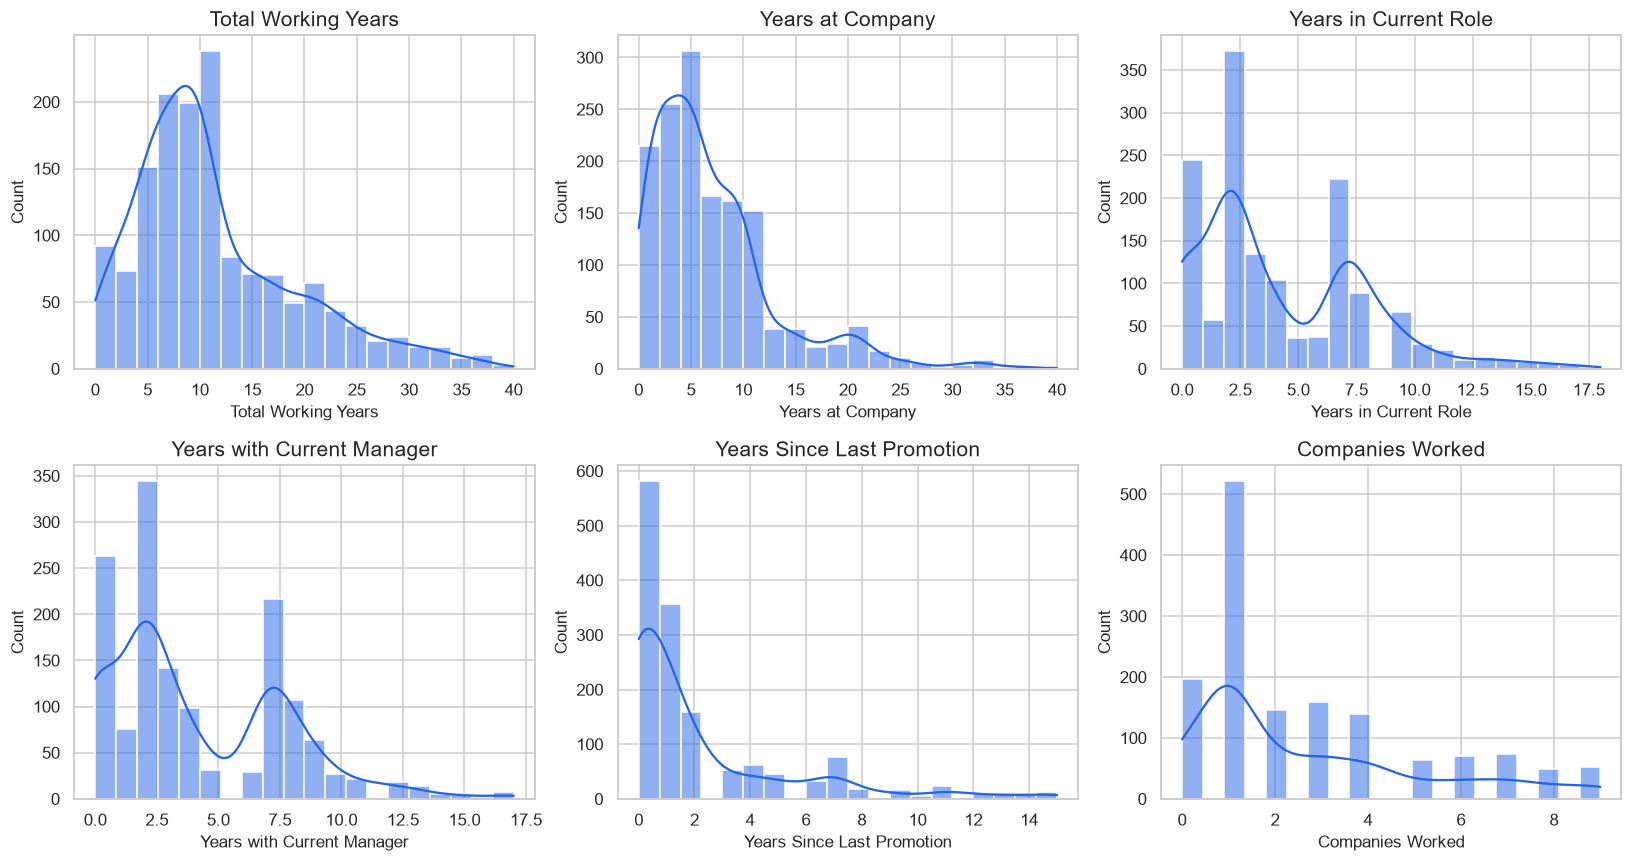

Total Working Years


Attrition,No,Yes
count,1233.000000,237.000000
mean,11.862936,8.244726
median,10.000000,7.000000


Years at Company


Attrition,No,Yes
count,1233.000000,237.000000
mean,7.369019,5.130802
median,6.000000,3.000000


Years in Current Role


Attrition,No,Yes
count,1233.000000,237.000000
mean,4.484185,2.902954
median,3.000000,2.000000


... (3 outputs left out)

Attrition,No,Yes
count,1233.000000,237.000000
mean,2.234388,1.945148
median,1.000000,1.000000


Companies Worked


Attrition,No,Yes
count,1233.00000,237.000000
mean,2.64558,2.940928
median,2.00000,1.000000


,Tenure Group,employees,attrition_count,attrition_rate
0,0-2 years,342,102,29.824561
1,3-5 years,434,60,13.824885
2,6-10 years,448,55,12.276786
3,11+ years,246,20,8.130081


In [13]:

experience_columns = ["Total Working Years","Years at Company","Years in Current Role",
                      "Years with Current Manager","Years Since Last Promotion","Companies Worked"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, experience_columns):
    sns.histplot(hr_clean[column], bins=20, kde=True, ax=ax, color="#2563eb")
    ax.set_title(column)
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "experience_distributions.png")
plt.show()

for column in experience_columns:
    print(column)
    display(hr_clean.groupby("Attrition")[column].agg(["count","mean","median"]).T)

tenure_attrition = attrition_rate_table("Tenure Group")
display(tenure_attrition)


Experience measures reveal tenure patterns and possible career-growth gaps. Attrition differences across tenure groups are descriptive and should be checked with current employee conditions.

## Correlation and Statistical Analysis

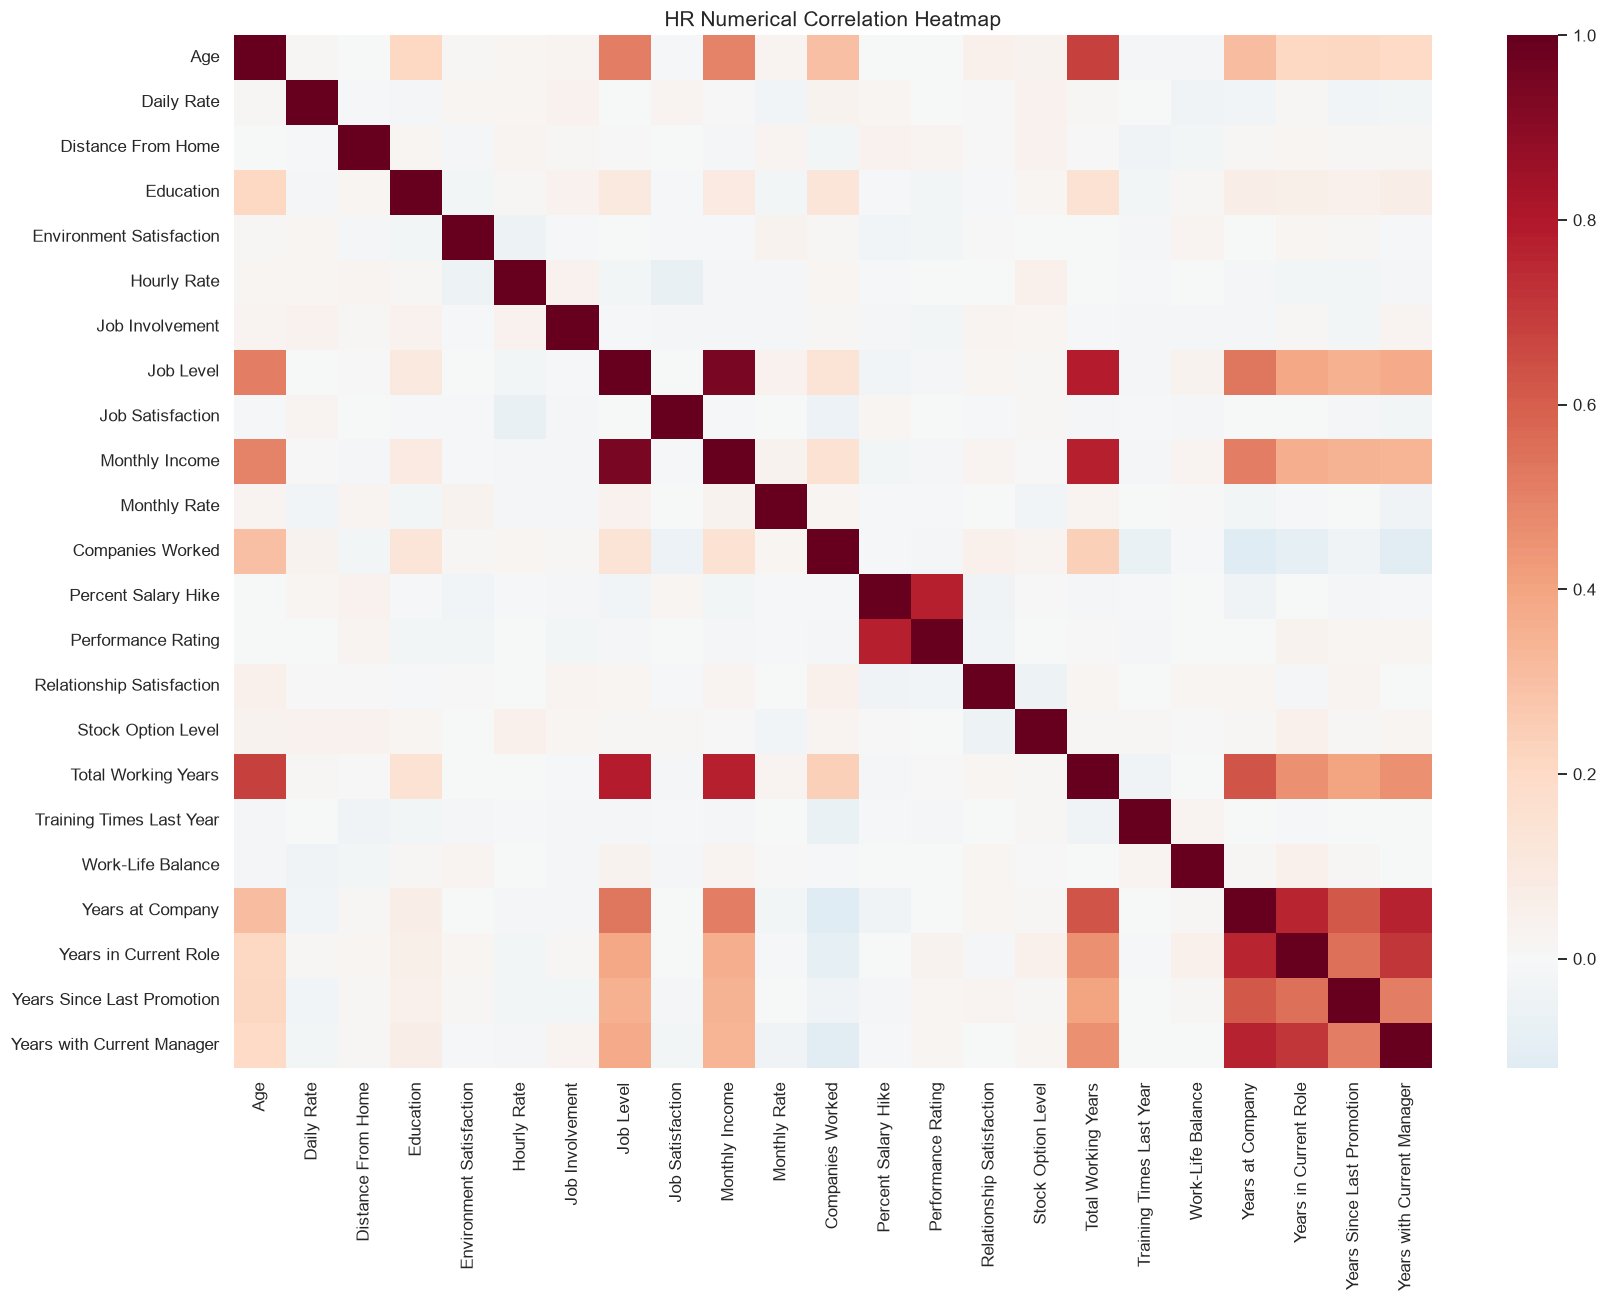

Age: 0 observations outside 1.5 x IQR
Monthly Income: 114 observations outside 1.5 x IQR
Total Working Years: 63 observations outside 1.5 x IQR
Years at Company: 104 observations outside 1.5 x IQR
Years Since Last Promotion: 107 observations outside 1.5 x IQR


In [14]:

numeric_hr = hr_clean.select_dtypes(include=[np.number]).copy()
numeric_hr = numeric_hr.drop(columns=["Employee Number"], errors="ignore")
corr_hr = numeric_hr.corr()

fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(corr_hr, cmap="RdBu_r", center=0, annot=False, ax=ax)
ax.set(title="HR Numerical Correlation Heatmap")
fig.tight_layout()
fig.savefig(project_root / "HR-Data-Analysis" / "outputs" / "charts" / "hr_correlation_heatmap.png")
plt.show()

for column in ["Age","Monthly Income","Total Working Years","Years at Company","Years Since Last Promotion"]:
    q1, q3 = hr_clean[column].quantile([0.25,0.75])
    iqr = q3-q1
    count = ((hr_clean[column] < q1-1.5*iqr) | (hr_clean[column] > q3+1.5*iqr)).sum()
    print(f"{column}: {count:,} observations outside 1.5 x IQR")


The correlation heatmap shows linear associations among numeric fields. It does not establish causation, and ordinal satisfaction fields are more carefully interpreted as rated categories.

## Save Cleaned and Summary Data

In [15]:

output_dir = project_root / "HR-Data-Analysis" / "outputs"
chart_dir = output_dir / "charts"
output_dir.mkdir(parents=True, exist_ok=True)
chart_dir.mkdir(parents=True, exist_ok=True)

hr_clean.to_csv(output_dir / "cleaned_hr_data.csv", index=False)
department_counts.to_csv(output_dir / "department_counts.csv", index=False)
dept_attrition.to_csv(output_dir / "department_attrition.csv", index=False)
role_attrition.to_csv(output_dir / "job_role_attrition.csv", index=False)
overtime_attrition.to_csv(output_dir / "overtime_attrition.csv", index=False)
department_salary.to_csv(output_dir / "department_average_salary.csv", index=False)
print("Saved cleaned and summary data to:", output_dir)


Saved cleaned and summary data to:

 C:\Users\gp298\Desktop\Afame-Technologies\HR-Data-Analysis\outputs


## HR Business Insights

In [16]:

highest_department_attrition = dept_attrition.iloc[0]
highest_role_attrition = role_attrition.iloc[0]
highest_age_attrition = age_attrition.iloc[0]
highest_overtime_attrition = overtime_attrition.iloc[0]
highest_travel_attrition = travel_attrition.iloc[0]
highest_job_sat_attrition = job_sat_attrition.iloc[0]
highest_wlb_attrition = wlb_attrition.iloc[0]
highest_tenure_attrition = tenure_attrition.iloc[0]
top_department = department_counts.iloc[0]
top_salary_department = department_salary.iloc[-1]

hr_insights = [
    ("Overall workforce attrition", f"{attrition_count:,} of {total_employees:,} employees ({attrition_rate:.2f}%)",
     "Attrition is present across the workforce.", "Establish retention review intervals and monitor trends by department."),
    ("Highest department attrition", f"{highest_department_attrition['Department']}: {highest_department_attrition['attrition_rate']:.2f}%",
     "This department has the highest observed attrition percentage.", "Review workloads, manager practices, and career paths within this department."),
    ("Highest role attrition", f"{highest_role_attrition['Job Role']}: {highest_role_attrition['attrition_rate']:.2f}%",
     "This role is a retention priority within the sample.", "Conduct stay interviews and role-level workload reviews."),
    ("Age group with highest attrition", f"{highest_age_attrition['Age Group']}: {highest_age_attrition['attrition_rate']:.2f}%",
     "Attrition differs across age groups.", "Tailor development and engagement programs rather than making individual assumptions."),
    ("Overtime pattern", f"{highest_overtime_attrition['OverTime']}: {highest_overtime_attrition['attrition_rate']:.2f}% attrition",
     "Overtime status is associated with different attrition percentages.", "Review overtime workload, staffing levels, and recovery practices."),
    ("Travel pattern", f"{highest_travel_attrition['Business Travel']}: {highest_travel_attrition['attrition_rate']:.2f}%",
     "Travel categories show different observed attrition.", "Check scheduling, travel burden, and support arrangements."),
    ("Job satisfaction pattern", f"Rating {highest_job_sat_attrition['Job Satisfaction']}: {highest_job_sat_attrition['attrition_rate']:.2f}%",
     "Job satisfaction ratings are associated with differing attrition.", "Focus on the lower-scoring groups and seek direct employee feedback."),
    ("Work-life balance pattern", f"Rating {highest_wlb_attrition['Work-Life Balance']}: {highest_wlb_attrition['attrition_rate']:.2f}%",
     "Work-life balance ratings differ by attrition rate.", "Review flexible work and workload policy at team level."),
    ("Tenure pattern", f"{highest_tenure_attrition['Tenure Group']}: {highest_tenure_attrition['attrition_rate']:.2f}%",
     "Attrition is uneven across tenure groups.", "Design retention actions around the identified tenure stage."),
    ("Largest department", f"{top_department['Department']}: {top_department['Employees']:,} employees",
     "This department is the largest workforce segment.", "Prioritize retention resources according to size and attrition risk."),
]
display(pd.DataFrame(hr_insights, columns=["Finding","Supporting numbers","Interpretation","Recommendation"]))


,Finding,Supporting numbers,Interpretation,Recommendation
0,Overall workforce attrition,"237 of 1,470 employees (16.12%)",Attrition is present across the workforce.,Establish retention review intervals and monit...
1,Highest department attrition,Sales: 20.63%,This department has the highest observed attri...,"Review workloads, manager practices, and caree..."
2,Highest role attrition,Sales Representative: 39.76%,This role is a retention priority within the s...,Conduct stay interviews and role-level workloa...
3,Age group with highest attrition,18-25: 35.77%,Attrition differs across age groups.,Tailor development and engagement programs rat...
4,Overtime pattern,Yes: 30.53% attrition,Overtime status is associated with different a...,"Review overtime workload, staffing levels, and..."
5,Travel pattern,Travel_Frequently: 24.91%,Travel categories show different observed attr...,"Check scheduling, travel burden, and support a..."
6,Job satisfaction pattern,Rating 1.0: 22.84%,Job satisfaction ratings are associated with d...,Focus on the lower-scoring groups and seek dir...
7,Work-life balance pattern,Rating 1.0: 31.25%,Work-life balance ratings differ by attrition ...,Review flexible work and workload policy at te...
8,Tenure pattern,0-2 years: 29.82%,Attrition is uneven across tenure groups.,Design retention actions around the identified...
9,Largest department,Research & Development: 961 employees,This department is the largest workforce segment.,Prioritize retention resources according to si...



## HR Recommendations
1. **Retention:** Prioritize departments and roles with the highest measured attrition rates.
2. **Overtime:** Review scheduling and staffing where overtime is associated with higher attrition.
3. **Work-life balance:** Use low work-life balance and satisfaction ratings as prompts for manager conversations.
4. **Career development:** Target tenure and promotion stages that show elevated attrition.
5. **Compensation review:** Compare salary patterns by role and level before drawing fairness conclusions.
6. **Training:** Check whether training frequency is linked to performance or retention rather than assuming a causal benefit.
7. **Employee feedback:** Survey employees directly to identify motivations that this dataset cannot measure.

## Final Conclusion
The HR analysis cleaned the real employee dataset, documented the removal of constant fields, created meaningful workforce groups, and evaluated department, role, overtime, travel, satisfaction, compensation, and tenure patterns in relation to attrition.

### Limitations
- The dataset is cross-sectional and does not include employee exit interviews.
- Satisfaction fields are ordinal scores.
- The analysis is descriptive and cannot prove causation.
- It does not capture every motivation or organizational factor involved in turnover.

### Future Scope
- Add longitudinal employee records.
- Model attrition only as an optional justified predictive task.
- Add exit survey and manager feedback data.
- Track promotion, internal mobility, and compensation changes over time.

## Author and Project Information
**Student:** [Add your name]  
**Organization:** AFAME Technologies  
**LinkedIn:** [Add your LinkedIn URL]  
**GitHub:** [Add your GitHub URL]
